# New Surveys: HSC, KiDS, UHS and Euclid

HostPhot v4 adds several surveys: the Hyper Suprime-Cam Subaru Strategic Program (HSC SSP PDR3), the Kilo-Degree Survey (KiDS DR5), the UKIRT Hemisphere Survey (UHS DR3) and Euclid (DR1 and Q1), as well as PACS 70 µm for Herschel, more HST instruments (ACS/WFC and NICMOS) and the Spitzer Heritage Archive mosaics. They are used in the same way as the other surveys. This example shows the first four, with a common aperture to compare them with other surveys.

In [1]:
import hostphot
print('HostPhot version:', hostphot.__version__)

HostPhot version: 4.0.0


In [2]:
import pandas as pd
from hostphot.utils import plot_image
from hostphot.cutouts import download_images
from hostphot.processing import coadd_images, create_mask
from hostphot.photometry import global_photometry as gp
from hostphot.surveys_utils import get_survey_filters

## Network settings

All the queries and downloads have a timeout (300 s by default), and the failed ones are retried and reported with warnings. For slow connections or large cutouts (e.g. Euclid or HSC), the timeout can be increased:

In [3]:
from hostphot.utils import set_network_timeout

set_network_timeout(600)  # seconds

## HSC and KiDS

HSC needs an account for the SSP data release: the username and password are read from the environment variables `HSC_SSP_USERNAME` and `HSC_SSP_PASSWORD`, which can be given in a `.env` file in the current directory (or a parent directory):

```
HSC_SSP_USERNAME = "username"
HSC_SSP_PASSWORD = "password"
```

HostPhot uses the HSC coadds without the local sky subtraction of the pipeline, which removes the extended light of large galaxies. KiDS images are downloaded from the ESO archive, with the zeropoint corrections of DR5.

NGC 5300, a spiral galaxy in the equatorial region covered by both surveys, is used here (only the i and Y bands of HSC cover it). The mask and the aperture are measured on a PanSTARRS coadd and applied to the HSC, KiDS and Legacy Survey images, so that the same region of the galaxy is measured in all of them:

In [4]:
name = 'NGC5300'
host_ra, host_dec = 207.0668, 3.9508

download_images(name, host_ra, host_dec, survey='PanSTARRS', size=7, overwrite=False)
download_images(name, host_ra, host_dec, survey='HSC', filters='iY', size=7, overwrite=False)
download_images(name, host_ra, host_dec, survey='KiDS', size=7, overwrite=False)
download_images(name, host_ra, host_dec, survey='LegacySurvey', size=7, overwrite=False)

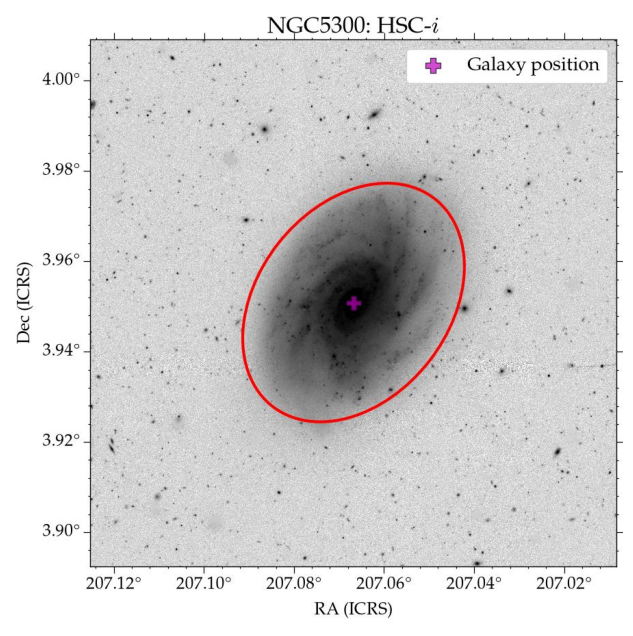

In [5]:
coadd_images(name, filters='riz', survey='PanSTARRS')
create_mask(name, host_ra, host_dec, filt='riz', survey='PanSTARRS', crossmatch=True, save_mask_params=True)
_ = gp.extract_aperture(name, host_ra, host_dec, filt='riz', survey='PanSTARRS')

results = {}
for survey, filters in [('PanSTARRS', 'griz'), ('HSC', 'iY'), ('KiDS', 'ugri'), ('LegacySurvey', 'grz')]:
    for filt in filters:
        create_mask(name, host_ra, host_dec, filt=filt, survey=survey,
                    ref_filt='riz', ref_survey='PanSTARRS', save_input=False)
    results[survey] = gp.multi_band_phot(name, host_ra, host_dec, filters=filters, survey=survey,
                                         common_aperture=True, ref_filt='riz', ref_survey='PanSTARRS',
                                         save_plots=True)
plot_image(f'images/{name}/HSC/global_HSC_i.jpg')

In [6]:
def table(results, filters):
    rows = {}
    for survey, df in results.items():
        rows[survey] = {f: f"{df[f].iloc[0]:.3f} ± {df[f'{f}_err'].iloc[0]:.3f}"
                        for f in filters if f in df.columns}
    return pd.DataFrame(rows).T

table(results, ['g', 'r', 'i', 'z'])

,g,r,i,z
PanSTARRS,12.450 ± 0.060,11.919 ± 0.040,11.689 ± 0.045,11.599 ± 0.036
HSC,NaN,NaN,11.353 ± 0.010,NaN
KiDS,12.658 ± 0.035,12.320 ± 0.033,11.928 ± 0.033,NaN
LegacySurvey,12.084 ± 0.010,11.544 ± 0.020,NaN,11.157 ± 0.015


The magnitudes of the same region of the galaxy differ between the surveys by several tenths of a magnitude, even though their calibrations agree for stars (within a few hundredths of a magnitude). The difference comes from the sky subtraction of the survey pipelines, which can remove part of the outskirts of large galaxies (NGC 5300 is ~4 arcmin across): HSC (whose coadds are used without the local sky subtraction of its pipeline) and the Legacy Survey agree, while PanSTARRS is ~0.4 mag fainter and KiDS is another ~0.2-0.4 mag fainter. For the fluxes of large galaxies, HSC or the Legacy Survey are preferable, while the other surveys can still be used for the masks and apertures. NGC 5300 is also at the edge of a KiDS tile: part of the aperture has no data, which is flagged (`coverage` flag).

## UHS

UHS covers the northern sky (from declination 0 to 60 degrees) in J and K (and H in part of it), not covered by UKIDSS. It is processed in the same way as UKIDSS (Vega magnitudes). Here, the mask and the aperture are measured on the UHS J image of NGC 7250 (the host of SN 2013dy), which is deeper and has a better resolution than 2MASS, and applied to the 2MASS images. NGC 7250 is a clumpy irregular galaxy, which the source detection splits into several objects: with the default masking (`method="ellipses"`), part of the galaxy would be masked as if it were a neighbour, so the model of the host is used (`method="host_model"`):

In [7]:
name = 'SN2013dy'
ra, dec = 334.573, 40.5693  # SN
host_ra, host_dec = 334.5740, 40.5624  # NGC 7250

download_images(name, host_ra, host_dec, survey='UHS', filters='JK', size=5, overwrite=False)
download_images(name, host_ra, host_dec, survey='2MASS', size=5, overwrite=False)

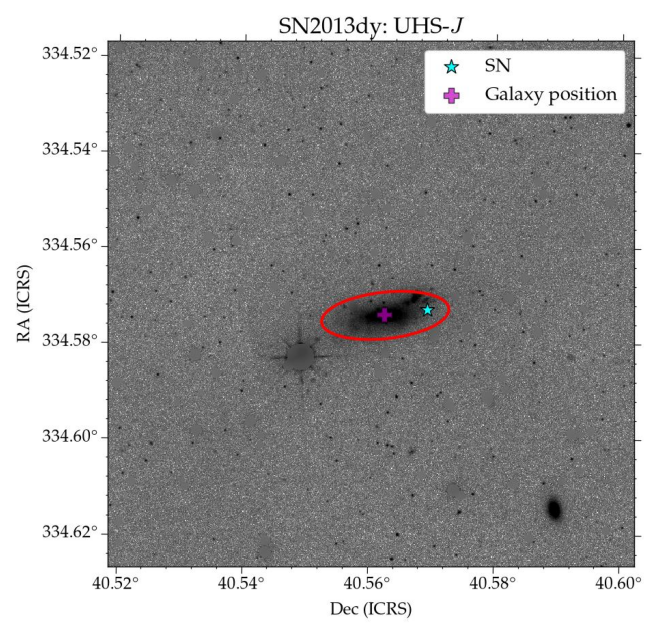

In [8]:
create_mask(name, host_ra, host_dec, filt='J', survey='UHS', ra=ra, dec=dec, method='host_model',
            crossmatch=True, save_mask_params=True)
_ = gp.extract_aperture(name, host_ra, host_dec, filt='J', survey='UHS', ra=ra, dec=dec)

results = {}
for survey, filters in [('UHS', 'JK'), ('2MASS', ['J', 'H', 'Ks'])]:
    for filt in filters:
        create_mask(name, host_ra, host_dec, filt=filt, survey=survey,
                    ref_filt='J', ref_survey='UHS', save_input=False)
    results[survey] = gp.multi_band_phot(name, host_ra, host_dec, filters=filters, survey=survey, ra=ra, dec=dec,
                                         common_aperture=True, ref_filt='J', ref_survey='UHS', save_plots=True)
plot_image(f'images/{name}/UHS/global_UHS_J.jpg')

In [9]:
table(results, ['J', 'H', 'K', 'Ks'])

,J,K,H,Ks
UHS,11.557 ± 0.026,10.753 ± 0.035,NaN,NaN
2MASS,11.524 ± 0.020,NaN,10.909 ± 0.029,10.673 ± 0.035


Note that the K filter of UHS (WFCAM) and the Ks filter of 2MASS are different, so their magnitudes are not expected to be identical.

## Euclid

Euclid's MER mosaics (VIS, and Y, J and H from NISP) are downloaded from IRSA, from DR1 by default (`version="Q1"` for the Quick Release 1). NGC 1404, an elliptical galaxy in the Fornax cluster that hosted two type Ia supernovae (SN 2007on and SN 2011iv), is covered by DR1:

In [10]:
name = 'SN2011iv'
ra, dec = 54.71396, -35.59222  # SN
host_ra, host_dec = 54.71638, -35.59411  # NGC 1404

download_images(name, host_ra, host_dec, survey='Euclid', size=6, overwrite=False)

In [11]:
create_mask(name, host_ra, host_dec, filt='VIS', survey='Euclid', ra=ra, dec=dec, save_mask_params=True)
_ = gp.extract_aperture(name, host_ra, host_dec, filt='VIS', survey='Euclid', ra=ra, dec=dec)

filters = get_survey_filters('Euclid')
for filt in filters:
    create_mask(name, host_ra, host_dec, filt=filt, survey='Euclid', ref_filt='VIS', ref_survey='Euclid',
                save_input=False)
euclid = gp.multi_band_phot(name, host_ra, host_dec, survey='Euclid', ra=ra, dec=dec,
                            common_aperture=True, ref_filt='VIS', ref_survey='Euclid', save_plots=True)
table({'Euclid': euclid}, filters)

,VIS,Y,J,H
Euclid,9.661 ± 0.011,8.980 ± 0.016,8.759 ± 0.030,8.636 ± 0.019


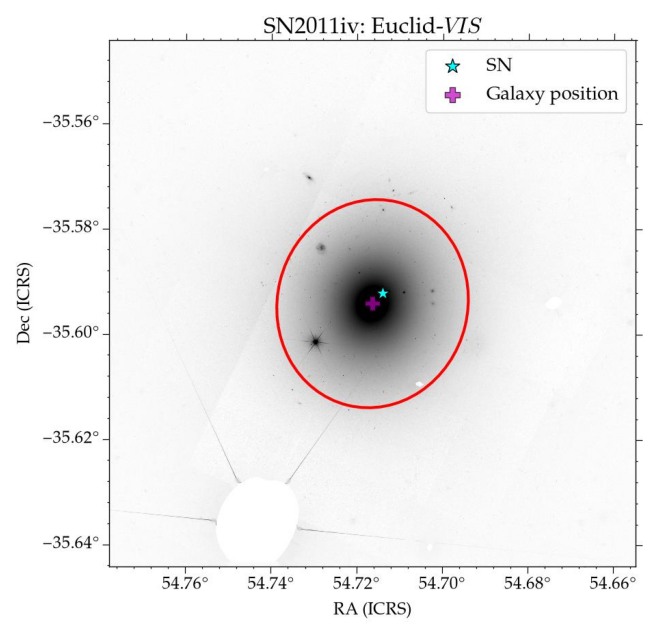

In [12]:
plot_image(f'images/{name}/Euclid/global_Euclid_VIS.jpg')

## Provenance

The images saved by HostPhot include keywords with their provenance (`HP*`): the HostPhot version (`HPVERS`), the download date (`HPDATE`), the survey (`HPSURVEY`), the size of the cutout (`HPSIZE`) and, for the surveys with several versions, the version used (`HPDATAV`, e.g. the data release), as well as the source file when available (`HPSOURCE`, e.g. the coadd tile, or the file of HST or JWST images given by the user). The photometry outputs include an identifier of each image (`{filt}_image_id`) and its download date:

In [13]:
from astropy.io import fits

header = fits.getheader(f'images/{name}/Euclid/Euclid_VIS.fits')
for key in header:
    if key.startswith('HP'):
        print(f'{key:8s} = {header[key]}')

HPDATAV  = dr1
HPVERS   = 4.0.0
HPDATE   = 2026-11-19T11:52:14
HPSURVEY = Euclid
HPSIZE   = 6.0


In [14]:
euclid[['hostphot_version', 'VIS_image_id', 'VIS_download_date']]

,hostphot_version,VIS_image_id,VIS_download_date
0,4.0.0,tile 102034973 dr1,2026-11-19T11:52:14
